# K-Nearest Neighbors

K-NN keeps every training penguin. To classify a new one, it finds the **K closest penguins** and goes with the majority.

This notebook goes with the **K-Nearest Neighbors** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split into train and test → scale → fit the model → check the result → draw the decision boundary.

## 1. Load the data

Each row is a penguin. We have two measurements (**bill length** and **body mass**) and the species. The goal: predict whether a penguin is an **Adelie** or a **Chinstrap** from those two numbers.

The data is the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) data set (CC0), reduced to two species and two columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/penguins.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,species,bill_length_mm,body_mass_g
0,Adelie,39.1,3750
1,Adelie,39.5,3800
2,Adelie,40.3,3250
3,Adelie,36.7,3450
4,Adelie,39.3,3650


In [2]:
X = dataset[['bill_length_mm', 'body_mass_g']].values
y = (dataset['species'] == 'Chinstrap').astype(int).values  # 0 = Adelie, 1 = Chinstrap

print(X.shape, 'penguins, class counts:', np.bincount(y))

(219, 2) penguins, class counts: [151  68]


## 2. Split into train and test

The model learns from the **training** penguins (75%). We keep the other 25% hidden and only use them at the end, so the test score shows how the model does on penguins it has never seen. Those are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

164 train, 55 test


## 3. Scale the features

**This step matters most for K-NN.** Body mass is in the thousands of grams while bill length is under 60 mm, so without scaling, body mass would decide every distance. Try skipping the scaler and compare the accuracy.

`StandardScaler` shifts each feature to an average of 0 and a spread of 1. We fit it on the **training** data only, then apply it to both sets.

In [4]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

## 4. Fit the model

This is the same code as on the lesson's Code tab (with `X_train_s` and `y_train`).

In [5]:
from sklearn.neighbors import KNeighborsClassifier
classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(X_train_s, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## 5. Check the result

The **confusion matrix** counts right and wrong guesses: the diagonal is correct, everything else is a mistake. **Accuracy** is the share of test penguins the model got right.

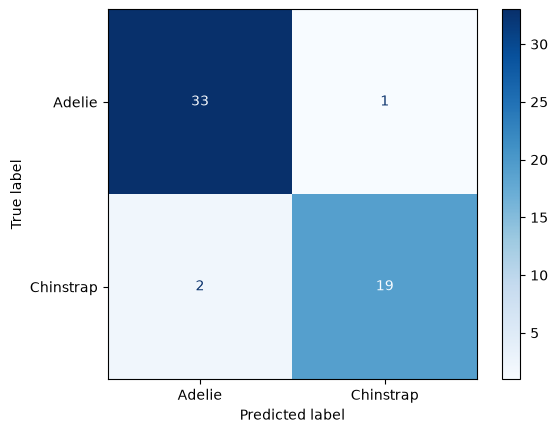

Test accuracy:  0.945
Train accuracy: 0.988


In [6]:
y_pred = classifier.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Adelie', 'Chinstrap']).plot(cmap='Blues')
plt.show()

print('Test accuracy: ', round(accuracy_score(y_test, y_pred), 3))
print('Train accuracy:', round(accuracy_score(y_train, classifier.predict(X_train_s)), 3))

## 6. Draw the decision boundary

We ask the model to classify every point on a grid and colour each cell by its answer. The boundary follows the data. Change `n_neighbors` and run the cells again to see it get smoother or more jagged.

C:\jtmp\ipykernel_29176\4074307720.py:10: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')


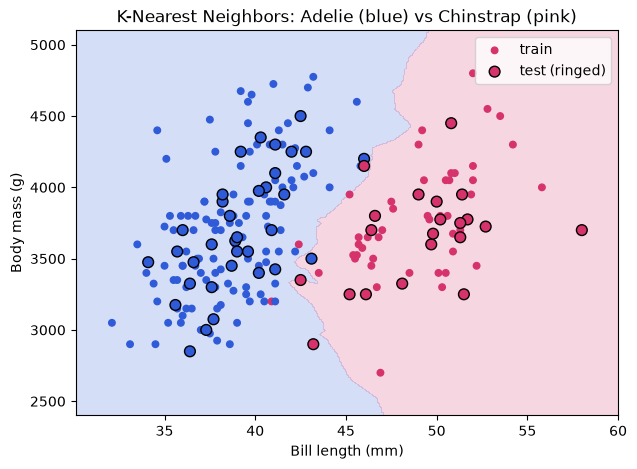

In [7]:
# a grid over the real units (mm and grams), scaled the same way as the training data
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

colors = ['#2f5bd8', '#d6336c']
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.2, levels=[-0.5, 0.5, 1.5], colors=colors)
plt.scatter(X_train[:, 0], X_train[:, 1], c=[colors[v] for v in y_train], s=22, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')
plt.xlabel('Bill length (mm)')
plt.ylabel('Body mass (g)')
plt.title('K-Nearest Neighbors: Adelie (blue) vs Chinstrap (pink)')
plt.legend()
plt.show()

## Try it yourself

- Set `n_neighbors=1`, then `n_neighbors=25`. Compare the training and test accuracy each time.
- Remove the `StandardScaler` lines and watch the accuracy drop.

## See it: the decision boundary

Each coloured area is where the model answers "Adelie" (blue) or "Chinstrap" (raspberry). **Notice how** the boundary follows the data, bending around small groups of penguins. A bigger `n_neighbors` would smooth it. The left panel shows the penguins the model learned from (filled dots). The right panel shows the penguins it has never seen (ringed dots): a ring sitting inside the wrong colour is a mistake. The accuracy is in each title.

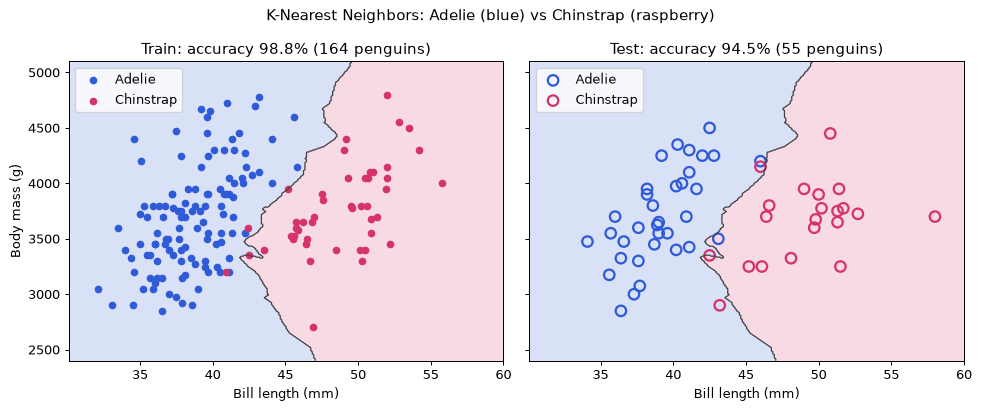

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
colors = [BLUE, PINK]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, Xp, yp, Xs in [(axes[0], 'Train', X_train, y_train, X_train_s),
                             (axes[1], 'Test', X_test, y_test, X_test_s)]:
    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5], colors=colors)
    ax.contour(xx, yy, zz, levels=[0.5], colors='#444444', linewidths=1)
    acc = (classifier.predict(Xs) == yp).mean()
    for cls, label in [(0, 'Adelie'), (1, 'Chinstrap')]:
        pts = Xp[yp == cls]
        if name == 'Train':
            ax.scatter(pts[:, 0], pts[:, 1], color=colors[cls], s=26, label=label)
        else:
            ax.scatter(pts[:, 0], pts[:, 1], facecolors='none', edgecolors=colors[cls], s=70, linewidths=1.8, label=label)
    ax.set_title(f'{name}: accuracy {acc:.1%} ({len(Xp)} penguins)')
    ax.set_xlabel('Bill length (mm)')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Body mass (g)')
fig.suptitle('K-Nearest Neighbors: Adelie (blue) vs Chinstrap (raspberry)')
fig.tight_layout()
plt.show()
